# **Etapa 1** — Preparar ambiente e conferir versões

In [ ]:
import os, sys, importlib.metadata as md
print('Python:', sys.version.split()[0])
assert sys.version_info[:2] == (3, 12), 'Este roteiro requer Python 3.12. Altere a versão do runtime do Colab.'
%pip install -q "tf-keras==2.19.0" "virtualenv"
os.environ['TF_USE_LEGACY_KERAS'] = '1'
import tensorflow as tf
from tensorflow import keras
print('TensorFlow:', tf.__version__)
assert tf.__version__.startswith('2.19.'), 'Este notebook foi validado com TensorFlow 2.19.x.'
print('OK — treinamento pronto.')

Python: 3.12.13
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.6/5.6 MB 103.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 472.1/472.1 kB 29.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 130.0/130.0 kB 13.1 MB/s eta 0:00:00
TensorFlow: 2.19.0
OK — treinamento pronto.


# **Etapa 2** — Montar o Google Drive

In [ ]:
from pathlib import Path
from google.colab import drive
drive.mount('/content/drive')
ROOT = Path('/content/drive/MyDrive/VisaoIA')
DATA = ROOT / 'dataset'
DATA.mkdir(parents=True, exist_ok=True)
print('Pasta do dataset:', DATA)


Mounted at /content/drive
Pasta do dataset: /content/drive/MyDrive/VisaoIA/dataset


# **Etapa 3** — Montar o dataset

In [ ]:
# OPCIONAL — preparar exemplo de flores para a primeira aula
import shutil
arquivo = tf.keras.utils.get_file(
    'flower_photos.tgz',
    origin='https://storage.googleapis.com/download.tensorflow.org/example_images/flower_photos.tgz',
    extract=True
)
origem = Path(arquivo).parent / 'flower_photos'
exemplos = {'daisy':'margaridas', 'roses':'rosas', 'sunflowers':'girassois'}
for ingles, classe in exemplos.items():
    pasta = DATA / classe
    pasta.mkdir(exist_ok=True)
    existentes = [p for p in pasta.iterdir() if p.suffix.lower() in ('.jpg','.jpeg','.png')]
    if existentes:
        print(classe, '— preservadas', len(existentes), 'imagens já existentes')
        continue
    fontes = sorted((origem / ingles).glob('*.jpg'))[:100]
    for foto in fontes:
        shutil.copy2(foto, pasta / foto.name)
    print(classe, '— importadas', len(fontes), 'imagens')

228813984/228813984 [==============================] - 12s 0us/step
margaridas — importadas 100 imagens
rosas — importadas 100 imagens
girassois — importadas 100 imagens


# **Etapa 4** — Validar imagens e carregá-las

In [ ]:
import numpy as np
IMG_SIZE=(96,96)
SEED=42
BATCH=32
EXT={'.jpg','.jpeg','.png','.bmp','.gif'}
contagem={d.name:sum(p.suffix.lower() in EXT for p in d.iterdir() if p.is_file()) for d in DATA.iterdir() if d.is_dir()}
print('Imagens por classe:', contagem)
assert len(contagem)>=2, 'Crie pelo menos duas pastas de classes no Drive.'
assert min(contagem.values())>=10, 'Cada classe deve conter ao menos 10 imagens.'
train_ds=keras.utils.image_dataset_from_directory(
    str(DATA),validation_split=.2,subset='training',seed=SEED,
    image_size=IMG_SIZE,batch_size=BATCH,label_mode='int',shuffle=True)
val_ds=keras.utils.image_dataset_from_directory(
    str(DATA),validation_split=.2,subset='validation',seed=SEED,
    image_size=IMG_SIZE,batch_size=BATCH,label_mode='int',shuffle=True)
classes=list(train_ds.class_names)
assert len(classes)==len(val_ds.class_names)
print('Classes na ordem correta:',classes)
train_ds=train_ds.prefetch(tf.data.AUTOTUNE)
val_ds=val_ds.prefetch(tf.data.AUTOTUNE)

Imagens por classe: {'margaridas': 100, 'rosas': 100, 'girassois': 100}
Found 300 files belonging to 3 classes.
Using 240 files for training.
Found 300 files belonging to 3 classes.
Using 60 files for validation.
Classes na ordem correta: ['girassois', 'margaridas', 'rosas']


# **Etapa 5** — Criar rede neural convolucional (CNN)

In [ ]:
model=keras.Sequential([
    keras.layers.Input(shape=(96,96,3)),
    keras.layers.Conv2D(24,3,activation='relu',padding='same'),
    keras.layers.MaxPooling2D(),
    keras.layers.Conv2D(48,3,activation='relu',padding='same'),
    keras.layers.MaxPooling2D(),
    keras.layers.Conv2D(64,3,activation='relu',padding='same'),
    keras.layers.MaxPooling2D(),
    keras.layers.GlobalAveragePooling2D(),
    keras.layers.Dense(64,activation='relu'),
    keras.layers.Dense(len(classes),activation='softmax')
])
model.compile(optimizer='adam',loss='sparse_categorical_crossentropy',metrics=['accuracy'])
model.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d (Conv2D)             (None, 96, 96, 24)        672       
                                                                 
 max_pooling2d (MaxPooling2  (None, 48, 48, 24)        0         
 D)                                                              
                                                                 
 conv2d_1 (Conv2D)           (None, 48, 48, 48)        10416     
                                                                 
 max_pooling2d_1 (MaxPoolin  (None, 24, 24, 48)        0         
 g2D)                                                            
                                                                 
 conv2d_2 (Conv2D)           (None, 24, 24, 64)        27712     
                                                                 
 max_pooling2d_2 (MaxPoolin  (None, 12, 12, 64)        0

# **Etapa 6** — Treinar, avaliar e visualizar os resultados

Epoch 1/12
8/8 [==============================] - 8s 120ms/step - loss: 1.0966 - accuracy: 0.3167 - val_loss: 1.0867 - val_accuracy: 0.5000
Epoch 2/12
8/8 [==============================] - 2s 104ms/step - loss: 1.0625 - accuracy: 0.4917 - val_loss: 1.0450 - val_accuracy: 0.4333
Epoch 3/12
8/8 [==============================] - 2s 111ms/step - loss: 0.9958 - accuracy: 0.5625 - val_loss: 0.9813 - val_accuracy: 0.4667
Epoch 4/12
8/8 [==============================] - 1s 45ms/step - loss: 0.8932 - accuracy: 0.5500 - val_loss: 0.8828 - val_accuracy: 0.6333
Epoch 5/12
8/8 [==============================] - 1s 43ms/step - loss: 0.8469 - accuracy: 0.6750 - val_loss: 0.8980 - val_accuracy: 0.4667
Epoch 6/12
8/8 [==============================] - 1s 46ms/step - loss: 0.8404 - accuracy: 0.5833 - val_loss: 0.9156 - val_accuracy: 0.5167
Epoch 7/12
8/8 [==============================] - 1s 45ms/step - loss: 0.8230 - accuracy: 0.6292 - val_loss: 0.8692 - val_accuracy: 0.5000
Epoch 8/12
8/8 [========

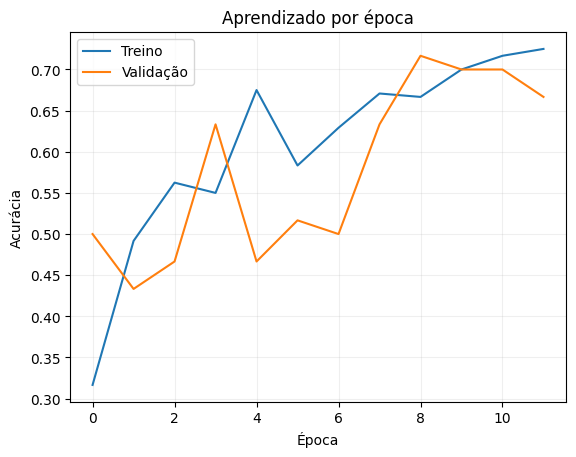

In [ ]:
train_norm=train_ds.map(lambda x,y:(x/255.0,y))
val_norm=val_ds.map(lambda x,y:(x/255.0,y))
history=model.fit(
    train_norm,validation_data=val_norm,epochs=12,
    callbacks=[keras.callbacks.EarlyStopping(monitor='val_loss',patience=4,restore_best_weights=True)]
)
loss,acc=model.evaluate(val_norm,verbose=0)
print(f'Acurácia de validação: {acc:.1%} | Perda: {loss:.4f}')
import matplotlib.pyplot as plt
plt.plot(history.history['accuracy'],label='Treino')
plt.plot(history.history['val_accuracy'],label='Validação')
plt.title('Aprendizado por época');plt.xlabel('Época');plt.ylabel('Acurácia');plt.legend();plt.grid(alpha=.2);plt.show()

# **Etapa 6** - Ajuste do treinamento

Epoch 1/20
8/8 [==============================] - 5s 108ms/step - loss: 0.6780 - accuracy: 0.7000 - val_loss: 0.6824 - val_accuracy: 0.7333 - lr: 1.0000e-04
Epoch 2/20
8/8 [==============================] - 1s 94ms/step - loss: 0.6737 - accuracy: 0.7250 - val_loss: 0.6942 - val_accuracy: 0.7000 - lr: 1.0000e-04
Epoch 3/20
8/8 [==============================] - 1s 94ms/step - loss: 0.6678 - accuracy: 0.7167 - val_loss: 0.6775 - val_accuracy: 0.7333 - lr: 1.0000e-04
Epoch 4/20
8/8 [==============================] - 1s 95ms/step - loss: 0.6690 - accuracy: 0.7292 - val_loss: 0.6794 - val_accuracy: 0.7167 - lr: 1.0000e-04
Epoch 5/20
8/8 [==============================] - 2s 96ms/step - loss: 0.6677 - accuracy: 0.7333 - val_loss: 0.6665 - val_accuracy: 0.7167 - lr: 1.0000e-04
Epoch 6/20
8/8 [==============================] - 2s 135ms/step - loss: 0.6646 - accuracy: 0.7417 - val_loss: 0.6579 - val_accuracy: 0.7167 - lr: 1.0000e-04
Epoch 7/20
8/8 [==============================] - 2s 143ms/ste

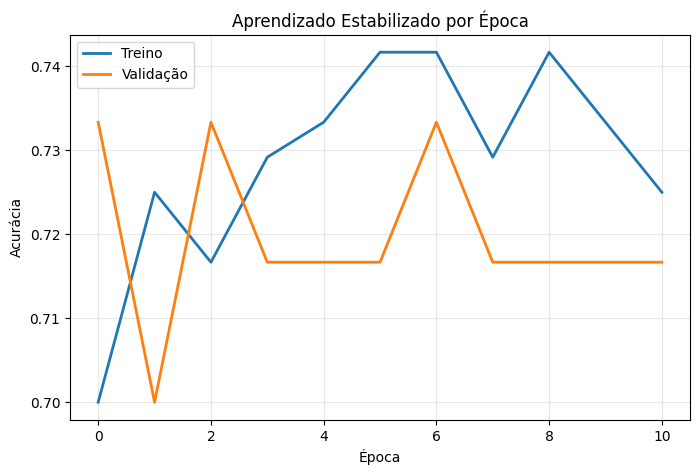

In [ ]:
import os
import random
import numpy as np
import tensorflow as tf
from tensorflow import keras
import matplotlib.pyplot as plt

# 1. FIXAR AS SEEDS (Garante que o treino não fique mudando drasticamente a cada execução)
SEED = 42
os.environ['PYTHONHASHSEED'] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

# 2. NORMALIZAÇÃO + DATA AUGMENTATION (Apenas no Treino)
data_augmentation = keras.Sequential([
    keras.layers.RandomFlip("horizontal"),
    keras.layers.RandomRotation(0.1),
    keras.layers.RandomZoom(0.1),
])

# Aplica normalização e augmentation no conjunto de treino
train_norm = train_ds.map(lambda x, y: (data_augmentation(x / 255.0, training=True), y))
val_norm = val_ds.map(lambda x, y: (x / 255.0, y))

# Otimiza a performance de leitura dos lotes
train_norm = train_norm.prefetch(tf.data.AUTOTUNE)
val_norm = val_norm.prefetch(tf.data.AUTOTUNE)

# 3. RECOMPILAR O MODELO COM UMA TAXA DE APRENDIZADO MENOR
optimizer = keras.optimizers.Adam(learning_rate=1e-4)
model.compile(
    optimizer=optimizer,
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# 4. CALLBACKS PARA REGULARIZAÇÃO
callbacks = [
    keras.callbacks.EarlyStopping(
        monitor='val_loss',
        patience=5,
        restore_best_weights=True
    ),
    keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.5,
        patience=2,
        verbose=1
    )
]

# 5. EXECUÇÃO DO TREINAMENTO
history = model.fit(
    train_norm,
    validation_data=val_norm,
    epochs=20,
    callbacks=callbacks
)

# Avaliação final
loss, acc = model.evaluate(val_norm, verbose=0)
print(f'\nAcurácia de validação: {acc:.1%} | Perda: {loss:.4f}')

# 6. GRÁFICO SUAVIZADO
plt.figure(figsize=(8, 5))
plt.plot(history.history['accuracy'], label='Treino', linewidth=2)
plt.plot(history.history['val_accuracy'], label='Validação', linewidth=2)
plt.title('Aprendizado Estabilizado por Época')
plt.xlabel('Época')
plt.ylabel('Acurácia')
plt.legend()
plt.grid(alpha=0.3)
plt.show()


# **Etapa 7** — Salvar o modelo treinado

In [ ]:
H5=Path('/content/visao_ia.h5')
model.save(str(H5))
assert H5.is_file() and H5.stat().st_size>0
print('Modelo salvo:',H5,'|',H5.stat().st_size,'bytes')

Modelo salvo: /content/visao_ia.h5 | 569440 bytes


/usr/local/lib/python3.12/dist-packages/tf_keras/src/engine/training.py:3098: UserWarning: You are saving your model as an HDF5 file via `model.save()`. This file format is considered legacy. We recommend using instead the native TF-Keras format, e.g. `model.save('my_model.keras')`.
  saving_api.save_model(


# **Etapa 8** — Converter em ambiente isolado (sequência validada)

In [ ]:
import subprocess, shutil
VENV=Path('/content/ambiente_tfjs')
EXPORT=Path('/content/modelo_exportado')
if VENV.exists(): shutil.rmtree(VENV)
if EXPORT.exists(): shutil.rmtree(EXPORT)
EXPORT.mkdir(parents=True)

def rodar(args, *, mostrar_erro=True):
    r=subprocess.run([str(x) for x in args],capture_output=True,text=True)
    if r.returncode!=0:
        if mostrar_erro:
            print('COMANDO:', ' '.join(map(str,args)))
            print((r.stdout+'\n'+r.stderr)[-10000:])
        raise RuntimeError(f'Etapa interrompida (código {r.returncode}). Leia o erro acima.')
    return r

print('1/4 — Criando ambiente virtual...')
rodar([sys.executable,'-m','virtualenv',str(VENV)])
VPY=VENV/'bin/python'
print('2/4 — Instalando TensorFlow.js no ambiente isolado...')
rodar([VPY,'-m','pip','install',
       'tensorflowjs==4.22.0','packaging==23.2',
       'tensorflow==2.19.0','tf-keras==2.19.0'])
print('3/4 — Ajustando dependências que causaram erro durante a aula...')
rodar([VPY,'-m','pip','install','--no-deps','protobuf==6.31.1','setuptools==80.9.0'])
verif=subprocess.run([str(VPY),'-m','pip','check'],capture_output=True,text=True)
print('Verificação de dependências (informativa):',verif.returncode)
if verif.stdout or verif.stderr: print((verif.stdout+verif.stderr)[-3000:])
print('4/4 — Convertendo HDF5 para TensorFlow.js...')
conv=VENV/'bin/tensorflowjs_converter'
r=subprocess.run([str(conv),'--input_format=keras',str(H5),str(EXPORT)],capture_output=True,text=True)
print('Código de retorno:',r.returncode)
if r.returncode!=0:
    print('DETALHES DO ERRO:',r.stderr[-12000:])
    raise RuntimeError('Conversão não concluída. Não é necessário refazer o treinamento: o H5 está salvo.')
assert (EXPORT/'model.json').is_file() and list(EXPORT.glob('*.bin'))
print('CONVERSÃO CONCLUÍDA:',[x.name for x in EXPORT.iterdir()])

1/4 — Criando ambiente virtual...
2/4 — Instalando TensorFlow.js no ambiente isolado...
3/4 — Ajustando dependências que causaram erro durante a aula...
Verificação de dependências (informativa): 1
tensorflow 2.19.0 has requirement protobuf!=4.21.0,!=4.21.1,!=4.21.2,!=4.21.3,!=4.21.4,!=4.21.5,<6.0.0dev,>=3.20.3, but you have protobuf 6.31.1.

4/4 — Convertendo HDF5 para TensorFlow.js...
Código de retorno: 0
CONVERSÃO CONCLUÍDA: ['model.json', 'group1-shard1of1.bin']


# **Etapa 9** — Criar o arquivo de classes e validar o resultado

In [ ]:
import json
(EXPORT/'classes.json').write_text(
    json.dumps({'classes':classes,'image_size':96},ensure_ascii=False,indent=2),encoding='utf-8')
info=json.loads((EXPORT/'classes.json').read_text(encoding='utf-8'))
assert info['classes']==classes and info['image_size']==96
assert (EXPORT/'model.json').exists()
assert len(list(EXPORT.glob('*.bin')))>=1
print('Categorias:',classes)
print('Arquivos exportados:',[p.name for p in EXPORT.iterdir()])

Categorias: ['girassois', 'margaridas', 'rosas']
Arquivos exportados: ['model.json', 'group1-shard1of1.bin', 'classes.json']


# **Etapa 10** — Gerar automaticamente o site completo

In [ ]:
SITE=Path('/content/visao_ia_site')
SITE.mkdir(parents=True,exist_ok=True)
print('Pasta da aplicação:', SITE)


# Criar o arquivo index.html automaticamente
(SITE / 'index.html').write_text('<!doctype html>\n<html lang="pt-BR">\n<head>\n  <meta charset="UTF-8" />\n  <meta name="viewport" content="width=device-width, initial-scale=1" />\n  <meta name="theme-color" content="#102a43" />\n  <title>Visão IA — Classificador de imagens</title>\n  <link rel="stylesheet" href="style.css" />\n  <script defer src="https://cdn.jsdelivr.net/npm/@tensorflow/tfjs@4.22.0/dist/tf.min.js"></script>\n  <script defer src="script.js"></script>\n</head>\n<body>\n  <main class="container">\n    <header><span class="eyebrow">PROJETO EDUCACIONAL · VISÃO COMPUTACIONAL</span><h1>Visão IA</h1><p>Classifique uma imagem usando um modelo treinado no Google Colab.</p></header>\n    <section class="panel">\n      <p id="status" role="status" aria-live="polite">Carregando modelo…</p>\n      <div class="actions">\n        <label class="button primary" for="gallery">Escolher imagem</label>\n        <input id="gallery" type="file" accept="image/*" hidden />\n        <label class="button" for="photo">Tirar foto (celular)</label>\n        <input id="photo" type="file" accept="image/*" capture="environment" hidden />\n        <button type="button" id="startCamera">Abrir câmera ao vivo</button>\n        <button type="button" id="takePhoto" disabled>Capturar da câmera</button>\n        <button type="button" id="stopCamera" disabled>Fechar câmera</button>\n      </div>\n      <div class="preview"><video id="video" autoplay playsinline muted hidden></video><img id="previewImage" alt="Imagem selecionada" hidden /><span id="placeholder">Sua imagem aparecerá aqui.</span></div>\n      <canvas id="captureCanvas" hidden></canvas>\n      <button type="button" id="classify" class="primary classify" disabled>Classificar imagem</button>\n    </section>\n    <section class="panel" aria-live="polite"><h2>Resultado</h2><p id="result">Selecione ou capture uma imagem para começar.</p><div id="scores"></div><p class="footnote">As pontuações representam as saídas do modelo, não garantias de acerto. As imagens são analisadas no próprio navegador.</p></section>\n  </main>\n</body>\n</html>\n', encoding='utf-8')
print('Criado: index.html')


# Criar o arquivo style.css automaticamente
(SITE / 'style.css').write_text(':root{font-family:system-ui,-apple-system,BlinkMacSystemFont,"Segoe UI",sans-serif;background:#f2f6fa;color:#102a43}*{box-sizing:border-box}body{margin:0}.container{width:min(820px,94%);margin:35px auto 60px}header{padding:15px 3px 20px}.eyebrow{font-size:.75rem;color:#356c99;letter-spacing:.13em;font-weight:800}h1{font-size:2.4rem;margin:7px 0}header p{color:#526779}.panel{padding:24px;background:#fff;border:1px solid #e2eaf0;box-shadow:0 6px 25px #102a4311;border-radius:18px;margin-bottom:18px}.actions{display:flex;flex-wrap:wrap;gap:10px;margin:20px 0}button,.button{appearance:none;border:1px solid #bdcddd;background:white;border-radius:10px;padding:12px 15px;font-weight:650;font-size:.95rem;color:#163d61;cursor:pointer;text-align:center}button.primary,.button.primary{background:#135d9c;border-color:#135d9c;color:white}button:disabled{opacity:.4;cursor:not-allowed}.preview{background:#f4f7fa;border:2px dashed #cbd9e3;border-radius:12px;min-height:190px;display:flex;justify-content:center;align-items:center;overflow:hidden;color:#687b8b}.preview video,.preview img{max-height:380px;width:100%;object-fit:contain}.preview video[hidden],.preview img[hidden]{display:none}.classify{margin-top:15px;width:100%;font-size:1.1rem}h2{font-size:1.2rem;margin:0 0 15px}.score{margin:12px 0}.scoreHead{display:flex;justify-content:space-between;margin-bottom:5px;font-size:.95rem}.track{height:10px;background:#e5eef6;border-radius:20px;overflow:hidden}.fill{height:100%;background:#2176b6;border-radius:20px}.footnote{font-size:.8rem;color:#687d8c;line-height:1.5}#status{margin:0;font-weight:650;color:#355c7d}@media(max-width:570px){.panel{padding:17px}.actions{display:grid;grid-template-columns:1fr 1fr}.actions>*{font-size:.83rem;padding:11px 7px}h1{font-size:2rem}}\n', encoding='utf-8')
print('Criado: style.css')


from pathlib import Path

SCRIPT_JS = r''''use strict';
const $ = id => document.getElementById(id);
let model = null;
let names = [];
let size = 96;
let stream = null;
let imageReady = false;
// Limiar didático. Ajustar após avaliar imagens de validação.
const LIMIAR_CONFIANCA = 0.80;
const status = text => { $('status').textContent = text; };
function stopCamera(){
  if (stream) { stream.getTracks().forEach(track => track.stop()); stream = null; }
  $('video').hidden = true;
  $('stopCamera').disabled = true;
  $('takePhoto').disabled = true;
}
function setImage(url){
  stopCamera();
  const img=$('previewImage');
  imageReady=false; $('classify').disabled=true;
  img.onload=()=>{imageReady=true;$('classify').disabled=!model;status('Imagem pronta para classificar.');};
  img.onerror=()=>status('Não foi possível abrir esta imagem.');
  img.src=url; img.hidden=false; $('placeholder').hidden=true;
  $('result').textContent='Clique em “Classificar imagem”.'; $('scores').replaceChildren();
}
function readFile(file){
  if (!file) return;
  if (!file.type.startsWith('image/')) {status('Escolha um arquivo de imagem.');return;}
  const reader=new FileReader(); reader.onload=()=>setImage(reader.result); reader.onerror=()=>status('Falha ao ler imagem.');reader.readAsDataURL(file);
}
$('gallery').addEventListener('change', e=>{readFile(e.target.files[0]);e.target.value='';});
$('photo').addEventListener('change', e=>{readFile(e.target.files[0]);e.target.value='';});
$('startCamera').addEventListener('click',async()=>{
  if (!navigator.mediaDevices?.getUserMedia){status('Câmera ao vivo indisponível. Use “Tirar foto” ou “Escolher imagem”.');return;}
  try{
    stopCamera();
    stream=await navigator.mediaDevices.getUserMedia({video:{facingMode:{ideal:'environment'}},audio:false});
    $('video').srcObject=stream; $('video').hidden=false; $('previewImage').hidden=true; $('placeholder').hidden=true;
    $('classify').disabled=true; imageReady=false;
    $('takePhoto').disabled=false; $('stopCamera').disabled=false;
    status('Câmera ligada. Clique em “Capturar da câmera”.');
  }catch(err){status('Não foi possível abrir a câmera: '+err.message+' — use a galeria se preferir.');}
});
$('takePhoto').addEventListener('click',()=>{
  const video=$('video');
  if (!stream || !video.videoWidth){status('Aguarde a câmera carregar.');return;}
  const canvas=$('captureCanvas');canvas.width=video.videoWidth;canvas.height=video.videoHeight;
  canvas.getContext('2d').drawImage(video,0,0);
  setImage(canvas.toDataURL('image/jpeg',0.92));
});
$('stopCamera').addEventListener('click',()=>{stopCamera();$('placeholder').hidden=!$('previewImage').hidden;status('Câmera desligada.');});
window.addEventListener('pagehide',stopCamera);
$('classify').addEventListener('click',async()=>{
  if(!model || !imageReady)return;
  $('classify').disabled=true; status('Classificando…');
  try{
    // Mesmo pré-processamento do Colab v2: RGB, 96 × 96, valores / 255.
    const scores=await tf.tidy(()=>{
      const pixels=tf.browser.fromPixels($('previewImage'),3);
      const batch=tf.image.resizeBilinear(pixels,[size,size]).toFloat().div(255).expandDims(0);
      const out=model.predict(batch);
      return Array.from(out.dataSync());
    });
    if(scores.length!==names.length)throw new Error(`Modelo possui ${scores.length} saídas, mas classes.json possui ${names.length} categorias.`);
    const ranked=scores.map((p,i)=>({p,name:names[i]})).sort((a,b)=>b.p-a.p);
    const melhor = ranked[0];
    if (melhor.p < LIMIAR_CONFIANCA) {
      $('result').textContent =
        `Classificação inconclusiva: maior pontuação de ${(melhor.p*100).toFixed(1)}% (${melhor.name}), abaixo do limiar de ${(LIMIAR_CONFIANCA*100).toFixed(0)}%.`;
    } else {
      $('result').textContent =
        `Classe mais provável: ${melhor.name} (${(melhor.p*100).toFixed(1)}%).`;
    }
    $('scores').replaceChildren();
    for(const item of ranked){
      const row=document.createElement('div');row.className='score';
      const head=document.createElement('div');head.className='scoreHead';
      const title=document.createElement('span');title.textContent=item.name;
      const number=document.createElement('span');number.textContent=(item.p*100).toFixed(1)+'%';
      head.append(title,number);const track=document.createElement('div');track.className='track';
      const fill=document.createElement('div');fill.className='fill';fill.style.width=Math.min(100,Math.max(0,item.p*100))+'%';
      track.append(fill);row.append(head,track);$('scores').append(row);
    }
    status('Classificação concluída.');
  }catch(err){status('Erro de classificação: '+err.message);console.error(err);}
  finally{$('classify').disabled=!imageReady||!model;}
});
(async()=>{
  try{
    if(typeof tf==='undefined')throw new Error('Biblioteca TensorFlow.js não carregou. Verifique sua conexão com a internet.');
    const response=await fetch('./model/classes.json');if(!response.ok)throw new Error(`classes.json: HTTP ${response.status}`);
    const classes=await response.json();
    if(!Array.isArray(classes.classes)||!classes.classes.length)throw new Error('classes.json não contém lista "classes".');
    names=classes.classes;size=Number(classes.image_size)||96;
    model=await tf.loadLayersModel('./model/model.json');
    status(`Modelo carregado: ${names.length} categorias. Escolha uma foto.`);
    $('classify').disabled=!imageReady;
  }catch(err){status('Modelo ainda não disponível: '+err.message);console.error(err);}
})();
'''
(SITE / 'script.js').write_text(SCRIPT_JS, encoding='utf-8')
print('script.js atualizado com limiar de 80%:', SITE / 'script.js')

Pasta da aplicação: /content/visao_ia_site
Criado: index.html
Criado: style.css
script.js atualizado com limiar de 80%: /content/visao_ia_site/script.js


# **Etapa 11** — Montar a pasta model, testar e criar ZIP pronto para o GitHub

In [ ]:
import zipfile, shutil
SITE_MODEL=SITE/'model'
if SITE_MODEL.exists():shutil.rmtree(SITE_MODEL)
shutil.copytree(EXPORT,SITE_MODEL)
for required in ['index.html','style.css','script.js','model/model.json','model/classes.json']:
    assert (SITE/required).is_file(),f'Arquivo ausente: {required}'
assert list(SITE_MODEL.glob('*.bin')),'Arquivo de pesos .bin ausente!'
ZIP=Path('/content/Visao_IA_SITE_PRONTO_GITHUB.zip')
with zipfile.ZipFile(ZIP,'w',compression=zipfile.ZIP_DEFLATED) as z:
    for file in SITE.rglob('*'):
        if file.is_file():z.write(file,file.relative_to(SITE).as_posix())
with zipfile.ZipFile(ZIP) as z:
    arquivos=z.namelist()
    assert 'index.html' in arquivos and 'model/model.json' in arquivos
print('SITE GERADO COM SUCESSO:',ZIP)
print('Arquivos contidos no ZIP:')
for f in arquivos:print('  ',f)

SITE GERADO COM SUCESSO: /content/Visao_IA_SITE_PRONTO_GITHUB.zip
Arquivos contidos no ZIP:
   script.js
   index.html
   style.css
   model/model.json
   model/group1-shard1of1.bin
   model/classes.json


# **Etapa 12** — Guardar backup no Drive e baixar o ZIP final

In [ ]:
BACKUP=ROOT/'publicacao'
BACKUP.mkdir(parents=True,exist_ok=True)
shutil.copy2(ZIP,BACKUP/ZIP.name)
shutil.copy2(H5,BACKUP/H5.name)
print('Backup salvo em:',BACKUP)
from google.colab import files
files.download(str(ZIP))

Backup salvo em: /content/drive/MyDrive/VisaoIA/publicacao


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>